# AudioCFG — prototyp: globalny null CFG uczony odszumianiem dla zamrożonego Stable Audio Open

WIMU 2026Z, zespół 06: Jan Konarski, Jakub Szewczyk, Vladyslav Serhieiev. Gałąź `feat/learned-null`.

Notatnik to jednocześnie **poprawiona propozycja projektu** i **raport z prototypu**: hipoteza, dokładna specyfikacja (uczony tensor, cel treningowy, dane, metryki, kryterium przewagi), polecenia do odtworzenia każdego kroku oraz wyniki. Wszystkie liczby są czytane z plików w `results/` (zacommitowanych razem z manifestami), więc notatnik wykonuje się na CPU w kilkanaście sekund i nie wymaga GPU ani pobierania audio.

**Spis treści**
1. Hipoteza i specyfikacja
2. Jak uruchomić i odtworzyć
3. Krok 1 — trening nulla (P0)
4. Krok 2 — przemiatanie CFG
5. Krok 3 — ocena: zgodność, jakość, różnorodność
6. Odsłuch A/B
7. Wnioski, kiedy działa, dalsze kroki
8. Powtórka: nowe prompty i nowe seedy

## 1. Hipoteza i specyfikacja

**Hipoteza.** Jeden globalny null, wyuczony błędem odszumiania przy zamrożonym Stable Audio Open 1.0, poprawia jakość generacji przy porównywalnej zgodności z opisem i różnorodności, ponad to, co daje samo dostrojenie skali CFG. Ten sam embedding działa dla nowych promptów bez ponownego treningu.

**Trzy kroki:**
1. Uczymy tylko null błędem odszumiania przy zamrożonym generatorze; porównujemy z oryginalnym SAO.
2. Dla obu wariantów robimy przemiatanie CFG na tych samych nowych promptach i seedach; dane oceny są rozłączne z danymi treningu nulla.
3. Oceniamy zgodność z opisem, jakość i różnorodność, sprawdzamy odsłuchem. Jeśli efekt nowego nulla można odtworzyć zmianą g w oryginale, przewagi nie ma.


### 1.1 Uczony tensor

| | |
|---|---|
| Tensor | `N ∈ R^{128×768}`: 98 304 parametry, fp32 |
| Miejsce | wyjście enkodera tekstu T5-base (128 tokenów × 768) w sekwencji cross-attention DiT, tylko w gałęzi bezwarunkowej CFG |
| Gałąź bezwarunkowa | `encoder_hidden_states_∅ = [N; 0; 0]` (130×768). Dwa sloty czasu zostają zerowe, tak jak w dropoucie warunku w treningu SAO. `global_hidden_states` (czas trwania) jest prawdziwy |
| Gałąź warunkowa | bez zmian: `[T5(opis); czas_start; czas_koniec]` |
| Inicjalizacja | `N = 0`, czyli punkt startowy to dokładnie oryginalny SAO |
| Zamrożone | wszystkie wagi SAO: DiT, VAE, T5, projekcje. Gradient dostaje tylko `N` (`tests/test_train.py`, sha256 wag w `configs/sao_sha256.json`) |
| Plik wynikowy | `results/null_music_v1/null_music_v1_learned_zero.safetensors` |

CFG w konwencji diffusers: `v̂ = v_∅ + g (v_c − v_∅)`, gdzie g = 1 oznacza brak guidance. Nasza pętla próbkowania z `N = 0` daje to samo co `StableAudioPipeline` (`tests/test_sao.py`). Oryginał to więc po prostu nasz kod z `N = 0`.

### 1.2 Cel treningowy

Strata odszumiania SAO (v-objective) liczona w samej gałęzi bezwarunkowej, bez CFG i bez żadnego sędziego:

`L(N) = E_{x₀, t, ε} ‖ v_θ(x_t, t, [N;0;0], czas) − v ‖²`, gdzie `x_t = α_t x₀ + σ_t ε`, `v = α_t ε − σ_t x₀`, `α_t = cos(πt/2)`, `σ_t = sin(πt/2)`, `t ~ U[0,001; 0,999]`, `ε ~ N(0, I)`, a `x₀` to latent VAE nagrania.

Minimalizujemy `L` tylko po `N`, więc null uczy się być lepszym modelem bezwarunkowym muzyki. To odróżnia nas od ReNeg, który optymalizuje ocenę sędziego (HPSv2.1).

| Hiperparametr | Wartość |
|---|---|
| Optymalizator | AdamW, weight decay 0 |
| lr | 5e-3, 100 kroków liniowego warmupu, potem cosinus do 0 |
| Kroki × batch | 1500 × 8 |
| Clip gradientu | 1,0 |
| Config | `configs/null_music_v1.yaml` |

Kontrole przed użyciem nulla (`results/null_music_v1/report.json`):
- **Poprawność parametryzacji:** L(prawdziwy opis) < L(0) na 64 parach z opisami.
- **Warunek P0:** L(N) < L(0) na walidacji, z 95% CI.

### 1.3 Dane

| Zbiór | Co | Ile | Plik |
|---|---|---|---|
| Trening nulla | utwory FMA, które były w treningu SAO, tylko audio, bez opisów; pierwsze ≤ 30 s, 44,1 kHz stereo, dopełnione ciszą do okna SAO, zakodowane VAE raz i zapisane w cache | 2000 (1999 po odrzuceniu 1 uszkodzonego) | `data/null_tracks.csv` (`split=train`) |
| Walidacja nulla | jak wyżej, inni artyści (podział po artyście) | 300 (299) | `data/null_tracks.csv` (`split=val`) |
| Kontrola parametryzacji | Song Describer z opisami, rozłączne z promptami oceny | 64 | `data/sanity_tracks.csv` |
| Ocena: muzyka | opisy z Song Describer (poprawny podzbiór, bez wokalu, jeden opis na utwór); audio z MTG-Jamendo, nie z FMA | 24 z 48 zamrożonych | `data/eval_prompts.csv` |
| Ocena: efekty | opisy `caption_1` ze zbioru ewaluacyjnego Clotho v2.1 | 24 z 48 zamrożonych | `data/eval_prompts.csv` |
| Referencja FD | utwory Song Describer, okno 10 s od 30. sekundy | 299 | `configs/score_pilot_A.yaml` |

Dane oceny są rozłączne z danymi uczenia nulla: inne źródła (Song Describer, Clotho kontra FMA) i inny typ danych (opisy kontra samo audio).

Przemiatanie (`configs/sweep_pilot_A.yaml`):
- 48 promptów × 3 seedy (zbiór A) × g ∈ {1, 2, 3, 4,5, 6, 7, 9, 12} × 2 nulle, czyli 2160 klipów. Przy g = 1 klip jest wspólny dla obu nulli.
- 10 s, 50 kroków samplera SAO.
- Oba nulle dostają identyczne prompty i szum startowy. Seed klipu wynika z seeda głównego 2026, promptu i numeru próbki.

### 1.4 Metryki

| Oś | Metryka | Szczegóły |
|---|---|---|
| Zgodność z opisem | CLAP | cosinus audio–tekst; `laion/larger_clap_music_and_speech` dla muzyki, `laion/larger_clap_general` dla efektów; rewizje przypięte w `configs/score_pilot_A.yaml` |
| Jakość (główna) | Audiobox Aesthetics PQ | Production Quality, przypięta rewizja |
| Jakość (pomocnicze) | Audiobox CE, CU, PC; FD | FD liczone w przestrzeni CLAP względem 299 utworów referencyjnych, osobno dla każdego (null, g); tylko muzyka |
| Różnorodność | CCDS | 1 − średnie podobieństwo cosinusowe CLAP między 3 klipami jednego promptu przy danym (null, g) |
| Odsłuch | ślepe A/B | 48 par muzycznych, jakość i zgodność z opisem, wyrównana głośność; odsetek wyboru wyuczonego nulla z 95% CI |

Null nie widział żadnej z tych metryk w treningu, więc ich wzrost nie jest „graniem pod sędziego”.

### 1.5 Kryterium przewagi nad oryginałem

Porównanie przy tej samej zgodności z opisem: dla każdego g z siatki nulla wyuczonego wyznaczamy `g*` nulla zerowego, przy którym średni CLAP jest taki sam (interpolacja liniowa krzywej CLAP(g)). Wtedy:

`ΔPQ(g) = PQ_learned(g) − PQ_zero(g*)`, analogicznie `ΔCCDS(g)`. 95% CI liczymy bootstrapem po promptach (2000 losowań, sparowane prompty, `g*` liczone od nowa w każdym losowaniu; `src/audiocfg/analysis/pareto.py`).

Wyuczony null ma przewagę, gdy dla g ∈ {6, 7, 9} jednocześnie:
1. ΔPQ > 0 i CI wyklucza 0,
2. różnorodność nie jest gorsza: dolna granica CI dla ΔCCDS leży powyżej −δ (test nie-gorszości). δ = 0,07 dla muzyki i 0,06 dla efektów, czyli połowa odchylenia standardowego CCDS między promptami dla nulla zerowego przy g = 7 w pilotażu A,
3. FD (tylko muzyka) zmienia się w tym samym kierunku co PQ: FD_learned(g) < FD_zero(g*),
4. warunki 1–3 zachodzą również w powtórce na nowych promptach i nowych seedach (sekcja 8),
5. odsłuch zgadza się co do kierunku.

Jeśli którykolwiek z punktów 1–3 nie zachodzi, efekt nowego nulla da się zastąpić zmianą g w oryginalnym SAO albo jest okupiony gorszą różnorodnością. Wtedy przewagi nie wykazaliśmy. Warunki 1–3 liczy automatycznie `audiocfg analyze --criterion configs/criterion_pilot_B.yaml` (`src/audiocfg/analysis/criterion.py`) i zapisuje je w `verdict.csv`.

**Kiedy ustaliliśmy kryterium.** Próg δ wyznaczyliśmy z wyników pilotażu A, więc werdykt dla A jest tylko pomocniczy. Rozstrzyga powtórka B: kryterium razem z δ zapisaliśmy w `configs/criterion_pilot_B.yaml` i zacommitowaliśmy, zanim powstał jakikolwiek klip B, więc wyniki B nie mogły na nie wpłynąć.

### 1.6 Jak wykorzystaliśmy prace z listy

Żadnej z tych prac nie przenieśliśmy w całości, bo żadna nie robi dokładnie tego eksperymentu. Z prac wzięliśmy metodę, interpretację i punkty odniesienia.

| Praca | Co wzięliśmy | Czego nie wzięliśmy i dlaczego |
|---|---|---|
| **ReNeg** (Li i in., 2024) | Główny wzorzec metody: jeden globalny embedding w gałęzi bezwarunkowej CFG, uczony przy zamrożonych wagach i używany potem na nowych promptach bez treningu. Optymalizator i harmonogram: AdamW, lr 5e-3, cosinus. | **Celu treningu.** ReNeg maksymalizuje ocenę sędziego (HPSv2.1) na obrazie przewidzianym w jednym kroku, a my minimalizujemy błąd odszumiania. **Oceny tym samym sędzią.** ReNeg raportuje wynik m.in. tym samym HPSv2.1, którego używa w treningu, a nasze metryki i odsłuch są niezależne od treningu. **Kontroli skali CFG.** ReNeg porównuje warianty przy stałym γ = 7,5, my przemiatamy g i sprawdzamy, czy efekt da się odtworzyć samym g. Mniej kroków i mniejszy batch niż w ReNeg (1500 × 8 zamiast 4000 × 64) wynikają z limitu GPU. Wariant „ReNeg dla audio” (null uczony pod ocenę, np. Audiobox, z niezależnym sędzią końcowym) zostawiamy na etap po powtarzalnej poprawie. |
| **Null-text Inversion** (Mokady i in., 2022) | Wzorzec optymalizacji embeddingu przy stałych wagach: parametrem jest tensor w przestrzeni wyjścia enkodera tekstu, gradient płynie tylko do niego, a model, enkoder i warunek są zamrożone. Inicjalizacja od embeddingu nulla używanego przez model (u nas zera, bo tak SAO był trenowany). | **Kodu nie użyliśmy wprost.** Jest napisany pod Stable Diffusion, sampler DDIM i odwracanie trajektorii obrazu, a SAO w diffusers ma inną architekturę (DiT, v-prediction, tokeny czasu). Pętlę napisaliśmy według tego samego wzorca (`src/audiocfg/train/loop.py`). **Procedury.** Null-text Inversion uczy osobny null dla każdego kroku czasu i dopasowuje go do jednego obrazu, więc nie daje globalnego nulla. My uczymy jeden null dla wszystkich nagrań, kroków i promptów. |
| **Learnable CFG Null Embeddings** (synteza mowy, 2026) | Punkt odniesienia dla pytania, czy wyuczony null zachowuje się lepiej przy dużej skali CFG. U autorów stały null psuje mowę przy dużym w, a wyuczony daje plateau. U nas podobnie: przy dużym g wyuczony null prawie nie przesterowuje (sekcja 4). | **Wspólnego treningu.** U autorów null jest uczony razem z generatorem od zera, a u nas generator jest gotowy i zamrożony, a null dopisany po treningu. Dlatego ich wyniku nie da się przenieść wprost i trzeba go sprawdzić eksperymentem. |
| **Classifier-Free Diffusion Guidance** (Ho i Salimans, 2022) | Podstawa interpretacji. CFG próbkuje w przybliżeniu z $p(x\mid c)\,[p(x\mid c)/p_\varnothing(x)]^{g-1}$, więc gałąź null wyznacza mianownik, czyli to, od czego guidance „odpycha”. Zmiana nulla zmienia kierunek guidance, a nie tylko jego siłę. Stąd konwencja skali (nasze g = 1 + w z pracy) i oczekiwany kompromis jakość–różnorodność przy rosnącym g, który widać w krzywych z sekcji 5. | — |

Jedna obserwacja z pracy o CFG jest kluczowa dla interpretacji. SAO był trenowany tak jak u Ho i Salimansa: w 10% przypadków cała sekwencja cross-attention była zastępowana zerami. Zerowy null w SAO jest więc już nullem wyuczonym razem z modelem. Nie zastępujemy „złego” nulla, tylko sprawdzamy, czy da się go poprawić po treningu przy zamrożonych wagach. To odróżnia nasz eksperyment od pracy o mowie, gdzie stały null był wektorem spoza rozkładu treningu.

### 1.7 Co jest nowe (wkład)

Samo uczenie nulla nie jest nowe: ReNeg uczy globalny embedding pod ocenę sędziego, Null-text Inversion dopasowuje null do jednego obrazu, a w syntezie mowy null uczy się razem z modelem. Nowe są u nas trzy rzeczy:
1. **Globalny null dopisany po treningu do zamrożonego generatora audio i uczony samym błędem odszumiania.** Nie ma tu sędziego, więc jakość i zgodność oceniamy metrykami i odsłuchem, których null nie widział w treningu.
2. **Kontrola strojenia CFG.** Każdy efekt nulla porównujemy z najlepszym, co daje sama skala g oryginału, przy tej samej zgodności z opisem (test przy tym samym CLAP z bootstrapem). Tej kontroli nie ma ReNeg ani praca o mowie.
3. **Ustalenie, kiedy to działa, a kiedy nie:** zależność od g, od domeny (muzyka kontra efekty) i od kosztu w różnorodności, złożoności i odległości od prawdziwej muzyki.

Stan na dziś (sekcje 5–8): hipoteza nie przeszła kryterium ani w pilotażu A, ani w powtórce B. Przewaga PQ przy tym samym CLAP w muzyce się powtarza, ale w B znika przy tym samym $g$, więc wynika głównie z niższego pułapu CLAP wyuczonego nulla. Różnorodność i FD są gorsze w obu zbiorach. Wkładem na dziś jest więc procedura (punkt 2) i wynik negatywny z kryterium zapisanym przed powtórką. Do publikacji potrzebny jest wariant nulla, który przejdzie kryterium na nowym zbiorze (dalsze kroki, sekcja 7).

## 2. Jak uruchomić i odtworzyć

**Instalacja** (Python ≥ 3.11):

```bash
git clone https://github.com/Nexonus/AudioCFG_WIMU_06_2026 && cd AudioCFG_WIMU_06_2026
git checkout feat/learned-null
python -m venv .venv && .venv/Scripts/activate      # Linux/macOS: source .venv/bin/activate
pip install -e ".[models,metrics,dev]"
pytest                                               # testy CPU (test GPU: pytest -m gpu)
```

Wagi SAO wymagają akceptacji licencji `stabilityai/stable-audio-open-1.0` na Hugging Face i `hf auth login`. Na Kaggle używamy lustrzanej kopii wag, której sha256 jest sprawdzany względem oficjalnych plików (`configs/sao_sha256.json`).

**Jedno polecenie na krok, jeden plik konfiguracyjny na krok:**

| Krok | Polecenie | Config | Wynik w repo |
|---|---|---|---|
| dane | `audiocfg prepare-data` | `configs/data.yaml` | `data/*.csv`, `data/data_manifest.json` |
| 1 | `audiocfg train-null <fma_large> <song_describer/audio>` | `configs/null_music_v1.yaml` | `results/null_music_v1/` |
| 2 | `audiocfg sweep --shard i --shards 2` → `audiocfg collect-sweep` | `configs/sweep_pilot_A.yaml` | `results/sweep_pilot_A/clips.parquet` |
| 3 | `audiocfg score <sweep_dir> --reference <song_describer/audio>` | `configs/score_pilot_A.yaml` | `results/score_pilot_A/` |
| analiza | `audiocfg analyze` | — | `results/analysis_pilot_A/*.csv` |
| powtórka | jak kroki 2–3 i analiza, z `--config configs/sweep_pilot_B.yaml` / `score_pilot_B.yaml`, potem `audiocfg analyze --score-dir results/score_pilot_B --out results/analysis_pilot_B` | `configs/*_pilot_B.yaml` | `results/*_pilot_B/` |
| odsłuch: pary | `audiocfg listen-pairs` | — | `results/listen_pilot_A/pairs.csv` (klucz: która strona to który null) |
| odsłuch: strona | `audiocfg listen-audio <sweep_dir>/audio` | — | `outputs/listen_pilot_A/` (`index.html` + mp3, poza gitem) |
| odsłuch: wynik | `audiocfg listen-tally` | — | `results/listen_pilot_A/tally.csv` z `answers/*.csv` |

`prepare-data` czyta listę FMA ∩ SAO oraz metadane Song Describer i Clotho v2.1 (Zenodo) ze ścieżek w `configs/data.yaml`; wynikowe CSV są zamrożone w `data/` (sha256 w `data/data_manifest.json`), więc do odtworzenia wyników nie trzeba ich generować ponownie.

**Odtworzenie samych liczb i wykresów (CPU, bez GPU):**

```bash
audiocfg analyze --score-dir results/score_pilot_A --out results/analysis_pilot_A --criterion configs/criterion_pilot_B.yaml
audiocfg analyze --score-dir results/score_pilot_B --out results/analysis_pilot_B --criterion configs/criterion_pilot_B.yaml
audiocfg listen-tally
jupyter execute --inplace notebooks/prototyp_audiocfg.ipynb   # Windows: najpierw set PYTHONUTF8=1
```

**Odsłuch.** `listen-audio` wymaga klipów ze sweepu (nasze kernele Kaggle są prywatne, więc audio trzeba wygenerować na własnym koncie: w `kaggle/sweep/kernel-metadata.json` zmienić `id` na `<nazwa_użytkownika_kaggle>/audiocfg`, uruchomić `python kaggle/push.py sweep`, po zakończeniu pobrać wynik `kaggle kernels output <nazwa_użytkownika_kaggle>/audiocfg -p outputs/kaggle_sweep` i podać `outputs/kaggle_sweep/sweep_pilot_A/audio` jako `audio_root`). Słuchacz otwiera `index.html` w przeglądarce (albo `python -m http.server` w tym folderze), wpisuje inicjały, ocenia 48 par i pobiera `INICJAŁY.csv`, który trafia do `results/listen_pilot_A/answers/`.

**Kaggle (2×T4).** Każdy krok ma gotowy job w `kaggle/<krok>/` (identyfikatory kerneli w `kernel-metadata.json` należą do naszego konta; przy własnym koncie wystarczy zmienić `id`). Skrypt `kaggle/push.py` odmawia wysłania, jeśli `src/` ma niezacommitowane zmiany albo commit nie jest na GitHubie, i wstrzykuje hash commita do joba — wynik zawsze odpowiada konkretnemu commitowi:

```bash
python kaggle/push.py null     # krok 1, ~2,7 h
python kaggle/push.py sweep    # krok 2, ~4,5 h na 2 GPU
python kaggle/push.py score    # krok 3, ~30 min
python kaggle/push.py sweep_B  # powtórka: prompty 24–47, seedy B (configs/sweep_pilot_B.yaml)
python kaggle/push.py score_B  # ocena powtórki (configs/score_pilot_B.yaml)
```

**Reprodukowalność.**
- Każdy seed jest wyprowadzany z jednego seeda głównego (`2026`) i z *tożsamości* elementu (np. `prompt_id`, numer próbki), nigdy z kolejności. Ten sam klip ma ten sam szum startowy i szum SDE przy każdym $g$ i obu nullach.
- Przy każdym wyniku jest `manifest.json`: commit, hash configu, wersje pakietów, GPU, sha256 wejść i wyjść.
- Modele oceny (CLAP, Audiobox) są przypięte do konkretnych rewizji na Hugging Face.
- Audio (≈2 GB FLAC na zbiór) nie jest w repo, bo kernele Kaggle są prywatne. Trzymamy tabele per klip (seed, metryki), a audio odtwarza się, uruchamiając joby na własnym koncie z tego samego commita.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from audiocfg.analysis.bootstrap import paired_ci
from audiocfg.analysis.pareto import curves, matched_clap_test, per_prompt, same_g_differences

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = ROOT / "results"

COLORS = {"zero": "#2a78d6", "learned": "#eb6834"}
LABELS = {"zero": "null zerowy (SAO)", "learned": "null wyuczony"}
DOMAINS = {"music": "muzyka (Song Describer)", "sfx": "efekty (Clotho)"}

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8985", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})


def end_label(ax, x, y, null):
    ax.annotate(LABELS[null], (x[-1], y[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color="#52514e")


def ci_text(ci, digits=5):
    return f"{ci['mean']:+.{digits}f}  [{ci['lo']:+.{digits}f}; {ci['hi']:+.{digits}f}]  (n={ci['n']})"

## 3. Krok 1 — trening nulla i warunek P0

**Ustawienia** (`configs/null_music_v1.yaml`): 2000 wycinków 30 s z FMA (utwory, które były w zbiorze treningowym SAO) do treningu i 300 do walidacji, podział **po artystach** (walidacja = artyści niewidziani w treningu). Init $N=0$ (czyli start dokładnie z domyślnego SAO), AdamW tylko na $N$, lr 5e-3 z rozgrzewką i cosinusem, batch 8, 1500 kroków, fp16 na T4.

**Dwa testy na stałych losowaniach $(t, \varepsilon)$** (te same dla każdego wariantu, więc porównania są parami):
- *test poprawności straty*: na 64 utworach Song Describer z opisami — czy własny opis daje niższą stratę niż null zerowy (jeśli nie, parametryzacja byłaby błędna);
- *P0*: czy na odłożonych artystach $\mathcal{L}(N) < \mathcal{L}(0)$. To warunek konieczny — bez niego nie ma sensu generować.

In [2]:
report = json.loads((RES / "null_music_v1/report.json").read_text())
rows = [
    ("test poprawności: L(0) − L(własny opis)", report["sanity"]["own_vs_zero"]),
    ("test poprawności: L(0) − L(cudzy opis)", {k: -v if k != "n" else v for k, v in report["sanity"]["wrong_vs_zero"].items()}),
    ("kontrola: L(0) − L(T5 pustego napisu)", {k: -v if k != "n" else v for k, v in report["t5_empty_vs_zero"].items()}),
    ("P0: L(0) − L(wyuczony N)", report["p0_learned_zero"]),
]
table = pd.DataFrame([{"porównanie": name, "średnia": ci["mean"], "95% CI dół": ci["lo"], "95% CI góra": ci["hi"], "n": ci["n"]} for name, ci in rows])
display(table.style.format({"średnia": "{:+.5f}", "95% CI dół": "{:+.5f}", "95% CI góra": "{:+.5f}"}).hide(axis="index"))

val = pd.read_csv(RES / "null_music_v1/val_losses.csv")
diff = val["zero"] - val["learned_zero"]
sanity = pd.read_csv(RES / "null_music_v1/sanity_losses.csv")
display(Markdown(
    f"- Wyuczony null obniża stratę w **{(diff > 0).mean():.0%}** utworów walidacyjnych; "
    f"własny opis obniża ją względem nulla zerowego w **{(sanity.zero_null > sanity.own_caption).mean():.0%}** utworów.\n"
    f"- Zysk z wyuczonego nulla to **{report['p0_learned_zero']['mean'] / report['sanity']['own_vs_zero']['mean']:.0%}** zysku, jaki daje prawdziwy opis utworu."
))

porównanie,średnia,95% CI dół,95% CI góra,n
test poprawności: L(0) − L(własny opis),+0.00135,+0.00042,+0.00260,64
test poprawności: L(0) − L(cudzy opis),+0.00073,+0.00217,-0.00038,64
kontrola: L(0) − L(T5 pustego napisu),-0.00001,+0.00000,-0.00003,299
P0: L(0) − L(wyuczony N),+0.00081,+0.00047,+0.00117,299


- Wyuczony null obniża stratę w **51%** utworów walidacyjnych; własny opis obniża ją względem nulla zerowego w **75%** utworów.
- Zysk z wyuczonego nulla to **60%** zysku, jaki daje prawdziwy opis utworu.

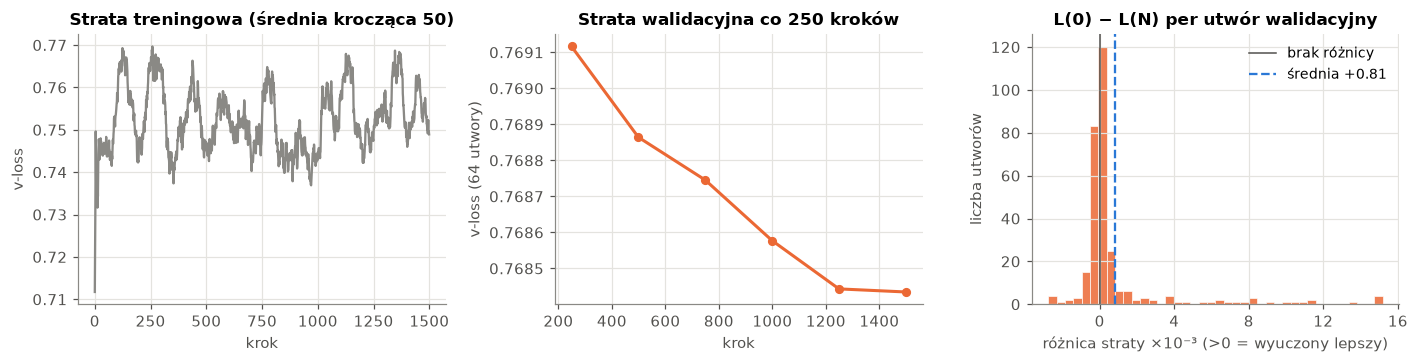

In [3]:
hist = pd.read_csv(RES / "null_music_v1/history_learned_zero.csv")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))

ax = axes[0]
ax.plot(hist.step, hist.loss.rolling(50, min_periods=1).mean(), color="#8a8985", lw=1.5)
ax.set(title="Strata treningowa (średnia krocząca 50)", xlabel="krok", ylabel="v-loss")

ax = axes[1]
v = hist.dropna(subset=["val_loss"])
ax.plot(v.step, v.val_loss, color=COLORS["learned"], marker="o", ms=5)
ax.set(title="Strata walidacyjna co 250 kroków", xlabel="krok", ylabel="v-loss (64 utwory)")

ax = axes[2]
d = diff * 1e3
lo, hi = d.quantile([0.01, 0.99])
ax.hist(d.clip(lo, hi), bins=40, color=COLORS["learned"], alpha=0.85, edgecolor="white", linewidth=0.5)
ax.axvline(0, color="#52514e", lw=1, label="brak różnicy")
ax.axvline(d.mean(), color=COLORS["zero"], lw=1.5, ls="--", label=f"średnia {d.mean():+.2f}")
ax.xaxis.set_major_locator(plt.MaxNLocator(6))
ax.legend(frameon=False, fontsize=9)
ax.set(title="L(0) − L(N) per utwór walidacyjny", xlabel="różnica straty ×10⁻³ (>0 = wyuczony lepszy)", ylabel="liczba utworów")
fig.tight_layout()

**Odczyt kroku 1.** Parametryzacja straty jest poprawna (własny opis < null zerowy). P0 jest spełniony: wyuczony null przewiduje odszumianie muzyki lepiej niż zerowy, a przedział ufności wyklucza 0. Efekt jest jednak mały w wartościach bezwzględnych i niesie go część utworów (rozkład różnic jest szeroki, środek blisko zera). Kontrola `T5("")` nie różni się od zera — efekt bierze się z treningu, nie z innej inicjalizacji.

## 4. Krok 2 — przemiatanie CFG

**Siatka (pilot, zbiór seedów A):** 24 prompty muzyczne (Song Describer, bez wokalu; audio z MTG-Jamendo, rozłączne z FMA) + 24 prompty efektów (Clotho v2, ewaluacja) × 3 seedy × $g \in \{1, 2, 3, 4.5, 6, 7, 9, 12\}$ × null ∈ {zero, wyuczony}. 50 kroków samplera SAO (CosineDPMSolver SDE), klipy 10 s. Klip przy $g=1$ nie używa gałęzi null, więc jest generowany raz i wspólny dla obu wariantów: 2160 generacji, 2304 wiersze.

Poniżej tylko diagnostyka sygnału (bez modeli oceniających): poziom szczytowy, odsetek próbek przesterowanych (|x| > 1) i norma $\lVert v_c - v_\varnothing\rVert$ (siła „pchnięcia” CFG) w trakcie próbkowania.

**2304** wierszy, **2160** unikalnych klipów, **48** promptów; commit `db825371`, GPU: Tesla T4, Tesla T4; mediana czasu generacji **15.5 s/klip**.

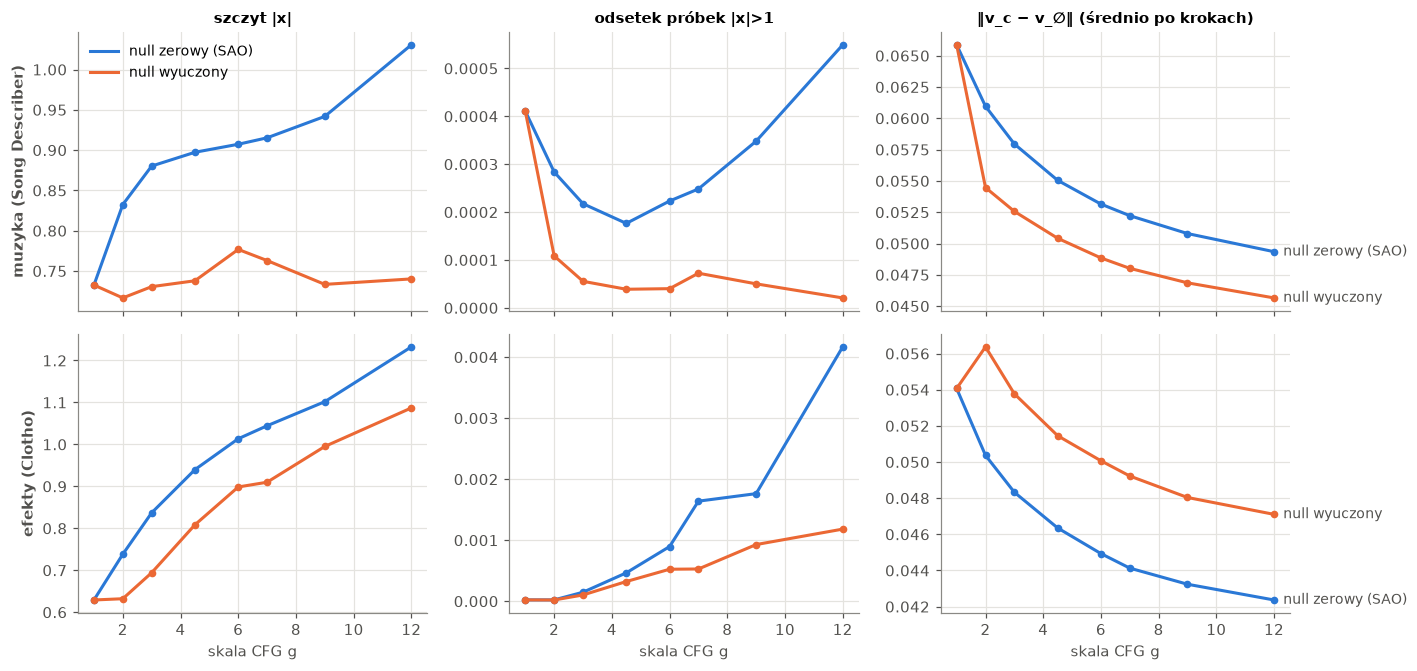

In [4]:
clips = pd.read_parquet(RES / "sweep_pilot_A/clips.parquet")
manifest = json.loads((RES / "sweep_pilot_A/manifest.json").read_text())
display(Markdown(
    f"**{len(clips)}** wierszy, **{clips['clip'].nunique()}** unikalnych klipów, "
    f"**{clips.prompt_id.nunique()}** promptów; commit `{manifest['git']['commit'][:8]}`, "
    f"GPU: {', '.join(manifest['device']['gpus'])}; mediana czasu generacji **{clips.seconds_per_clip.median():.1f} s/klip**."
))

fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), sharex=True)
for row, domain in enumerate(DOMAINS):
    sub = clips[clips.domain == domain]
    for col, (metric, title) in enumerate([("peak", "szczyt |x|"), ("clipped_frac", "odsetek próbek |x|>1"), ("guidance_rms_mean", "‖v_c − v_∅‖ (średnio po krokach)")]):
        ax = axes[row, col]
        for null in ("zero", "learned"):
            m = sub[sub.null == null].groupby("guidance")[metric].mean()
            ax.plot(m.index, m.values, color=COLORS[null], marker="o", ms=4)
            if col == 2:
                end_label(ax, m.index.values, m.values, null)
        ax.set_title(title if row == 0 else "", fontsize=10)
        if col == 0:
            ax.set_ylabel(DOMAINS[domain], fontsize=10, fontweight="bold")
        if row == 1:
            ax.set_xlabel("skala CFG g")
axes[0, 0].legend([plt.Line2D([], [], color=COLORS[n]) for n in COLORS], LABELS.values(), frameon=False, fontsize=9)
fig.tight_layout()

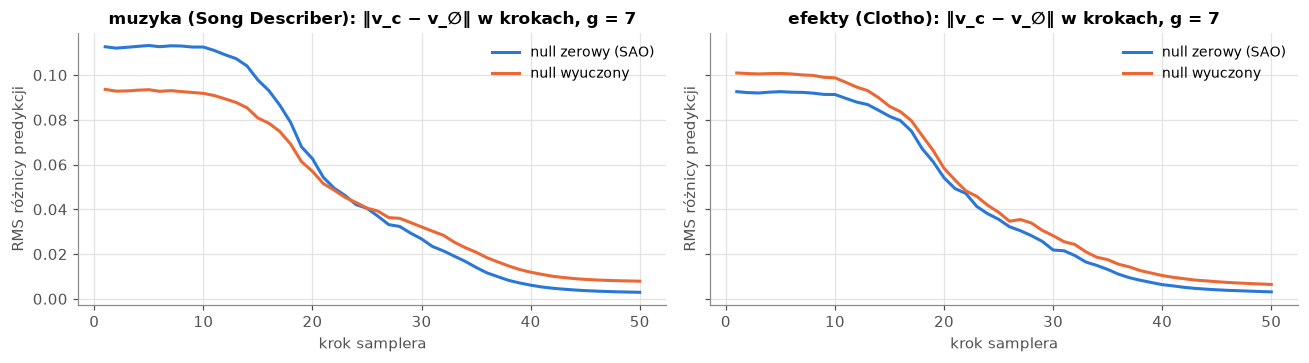

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, domain in zip(axes, DOMAINS):
    for null in ("zero", "learned"):
        sub = clips[(clips.domain == domain) & (clips.null == null) & (clips.guidance == 7)]
        steps = np.stack(sub.guidance_rms.to_numpy())
        ax.plot(np.arange(1, steps.shape[1] + 1), steps.mean(0), color=COLORS[null], label=LABELS[null])
    ax.legend(frameon=False, fontsize=9)
    ax.set(title=f"{DOMAINS[domain]}: ‖v_c − v_∅‖ w krokach, g = 7", xlabel="krok samplera", ylabel="RMS różnicy predykcji")
fig.tight_layout()

**Odczyt kroku 2.** Z nullem zerowym szczyt sygnału i przesterowanie rosną z $g$ (klasyczne przesycenie CFG). Z wyuczonym nullem rosną znacznie wolniej. W muzyce $\lVert v_c - v_\varnothing\rVert$ jest przy wyuczonym nullu mniejsze — to sygnał ostrzegawczy, że wyuczony null może działać jak *mniejsze g*. W efektach dźwiękowych ta norma jest większa, a przesterowania i tak mniej, więc tam to nie jest proste osłabienie guidance. Rozstrzyga dopiero krok 3.

## 5. Krok 3 — ocena

**Metryki** (`configs/score_pilot_A.yaml`, modele przypięte do rewizji HF):
- **zgodność z opisem — CLAP**: kosinus embeddingów audio i tekstu; muzyka: `laion/larger_clap_music_and_speech`, efekty: `laion/larger_clap_general` (drugi model liczony kontrolnie);
- **jakość — Audiobox Aesthetics** (Meta): PQ (production quality, metryka główna), CE (content enjoyment), CU (content usefulness), PC (production complexity);
- **różnorodność — CCDS**: średnia odległość kosinusowa embeddingów CLAP między 3 seedami tego samego promptu przy tym samym $g$ i nullu;
- **odległość od prawdziwej muzyki — FD na embeddingach CLAP** względem 300 nagrań Song Describer (tylko muzyka; dla Clotho nie mamy referencyjnego audio na Kaggle).

Uwaga o metodzie: żadna z tych metryk nie była celem treningu nulla (null uczony był wyłącznie stratą odszumiania), więc wzrost wyniku nie jest „grą pod sędziego”.

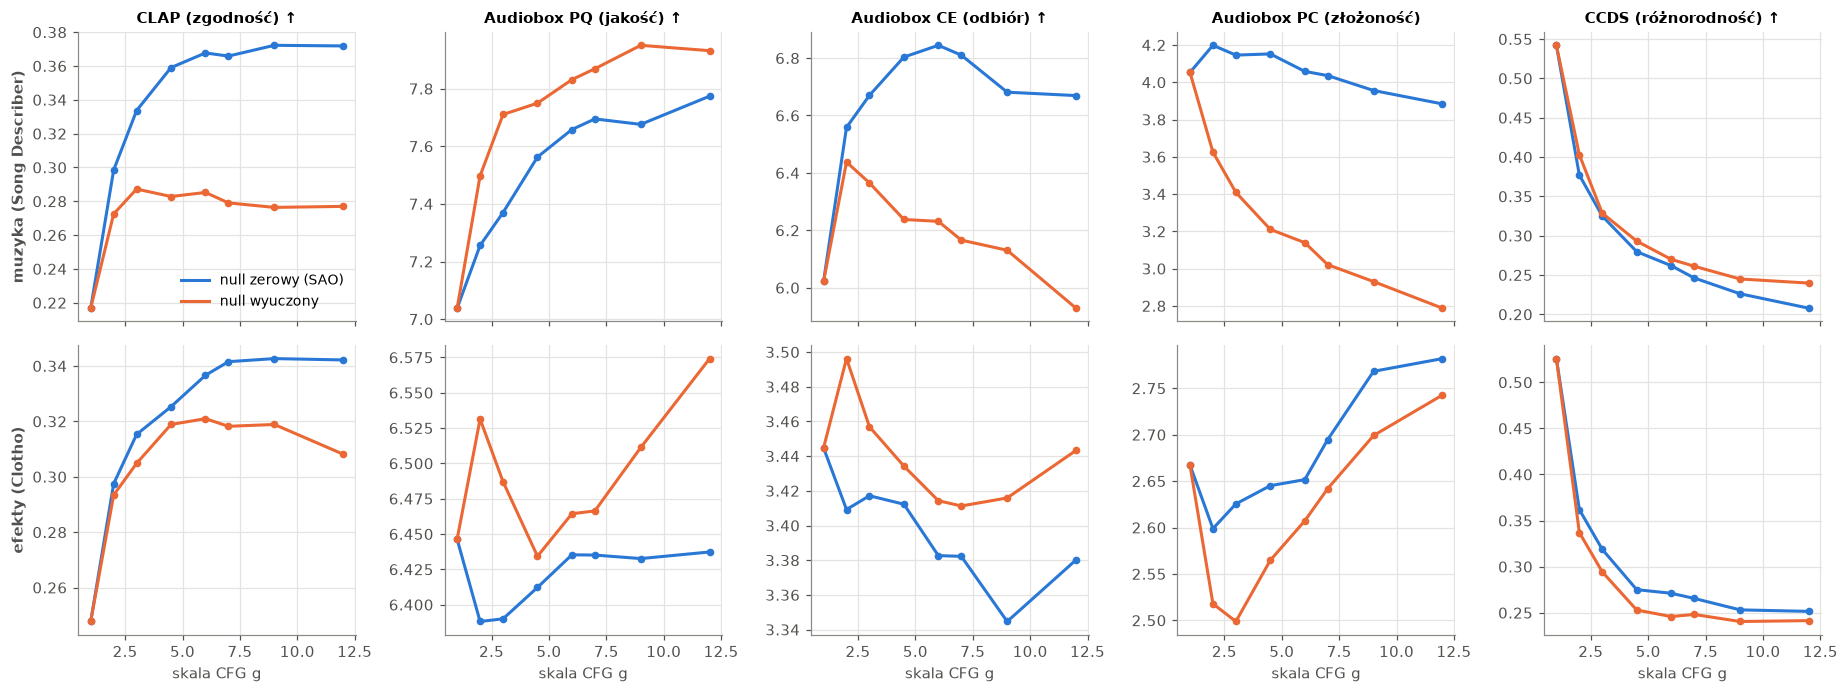

In [6]:
scores = pd.read_parquet(RES / "score_pilot_A/scores.parquet")
diversity = pd.read_parquet(RES / "score_pilot_A/diversity.parquet")
table = per_prompt(scores, diversity)
curve = curves(table)

fig, axes = plt.subplots(2, 5, figsize=(17, 6.4), sharex=True)
for row, domain in enumerate(DOMAINS):
    for col, (metric, title) in enumerate([("clap", "CLAP (zgodność) ↑"), ("PQ", "Audiobox PQ (jakość) ↑"), ("CE", "Audiobox CE (odbiór) ↑"), ("PC", "Audiobox PC (złożoność)"), ("ccds", "CCDS (różnorodność) ↑")]):
        ax = axes[row, col]
        for null in ("zero", "learned"):
            c = curve[(curve.domain == domain) & (curve.null == null)]
            ax.plot(c.guidance, c[metric], color=COLORS[null], marker="o", ms=4)
        ax.set_title(title if row == 0 else "", fontsize=10)
        if col == 0:
            ax.set_ylabel(DOMAINS[domain], fontsize=10, fontweight="bold")
        if row == 1:
            ax.set_xlabel("skala CFG g")
axes[0, 0].legend([plt.Line2D([], [], color=COLORS[n]) for n in COLORS], LABELS.values(), frameon=False, fontsize=9)
fig.tight_layout()

### Front jakość–zgodność

Każdy punkt to jedno $g$ (podpisane). Gdyby wyuczony null był tylko „innym $g$”, jego punkty leżałyby **na** krzywej nulla zerowego. Przewaga oznacza punkty **nad** nią (wyższa jakość przy tej samej zgodności).

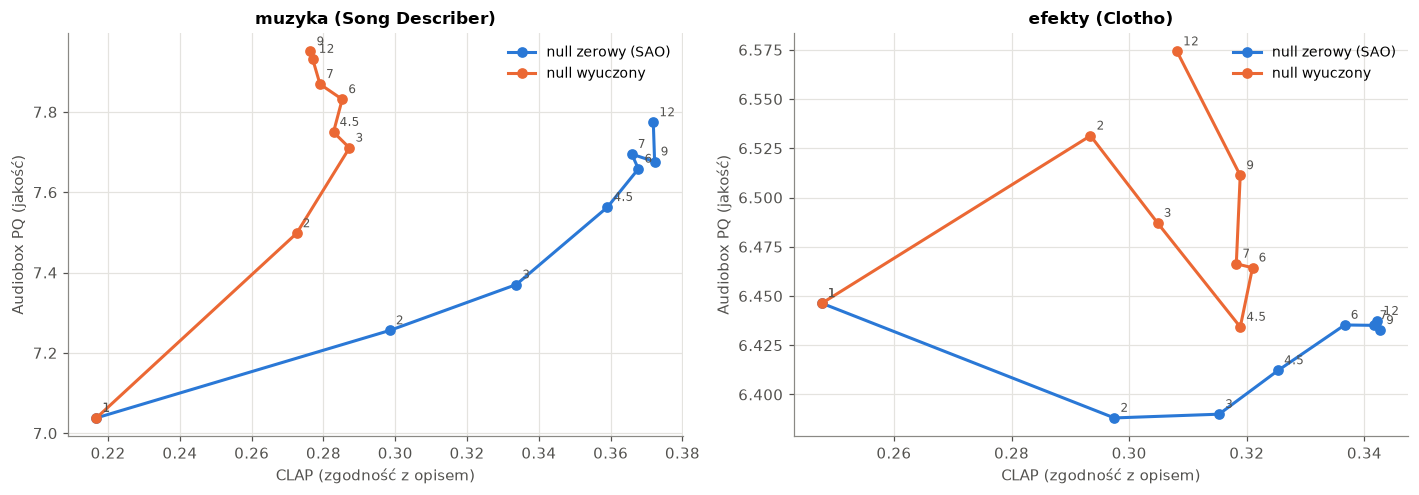

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, domain in zip(axes, DOMAINS):
    for null in ("zero", "learned"):
        c = curve[(curve.domain == domain) & (curve.null == null)].sort_values("guidance")
        ax.plot(c.clap, c.PQ, color=COLORS[null], marker="o", ms=6, label=LABELS[null])
        for _, r in c.iterrows():
            ax.annotate(f"{r.guidance:g}", (r.clap, r.PQ), xytext=(4, 4), textcoords="offset points", fontsize=8, color="#52514e")
    ax.set(title=DOMAINS[domain], xlabel="CLAP (zgodność z opisem)", ylabel="Audiobox PQ (jakość)")
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

### Test przy dopasowanym CLAP (kryterium z sekcji 1.5)

Dla każdego $g'$ wyuczonego nulla: $g^*$ = najmniejsze $g$ (interpolacja liniowa na siatce), przy którym null zerowy osiąga tę samą średnią CLAP; $\Delta = \text{metryka}(\text{wyuczony}, g') - \text{metryka}(\text{zero}, g^*)$. CI: bootstrap po promptach (2000 losowań, pary zachowane). `matched_frac` < 1 znaczy, że w części losowań null zerowy w ogóle nie osiąga takiej zgodności na siatce $g\in[1,12]$.

In [8]:
matched = matched_clap_test(table, metrics=("PQ", "ccds", "CE"), n_boot=2000)

def verdict(r):
    if np.isnan(r.lo):
        return "brak dopasowania"
    if r.lo > 0:
        return "wyuczony lepszy"
    if r.hi < 0:
        return "wyuczony gorszy"
    return "brak różnicy"

matched["wynik"] = matched.apply(verdict, axis=1)
show = matched[matched.metric == "PQ"].drop(columns="metric")
display(Markdown("**Δ PQ przy dopasowanym CLAP**"))
display(show.style.format({"g_star_zero": "{:.2f}", "delta": "{:+.3f}", "lo": "{:+.3f}", "hi": "{:+.3f}", "matched_frac": "{:.0%}"}).hide(axis="index"))
display(Markdown("**Δ CCDS (różnorodność) przy dopasowanym CLAP**"))
display(matched[matched.metric == "ccds"].drop(columns="metric").style.format({"g_star_zero": "{:.2f}", "delta": "{:+.4f}", "lo": "{:+.4f}", "hi": "{:+.4f}", "matched_frac": "{:.0%}"}).hide(axis="index"))

**Δ PQ przy dopasowanym CLAP**

domain,g_learned,g_star_zero,delta,lo,hi,matched_frac,wynik
music,2.000000,1.68,+0.311,+0.207,+0.420,100%,wyuczony lepszy
music,3.000000,1.86,+0.485,+0.334,+0.644,100%,wyuczony lepszy
music,4.500000,1.81,+0.536,+0.345,+0.736,100%,wyuczony lepszy
music,6.000000,1.84,+0.611,+0.418,+0.810,100%,wyuczony lepszy
music,7.000000,1.76,+0.665,+0.482,+0.850,100%,wyuczony lepszy
music,9.000000,1.73,+0.754,+0.546,+0.969,100%,wyuczony lepszy
music,12.000000,1.74,+0.733,+0.504,+0.984,100%,wyuczony lepszy
sfx,2.000000,1.92,+0.139,+0.065,+0.224,100%,wyuczony lepszy
sfx,3.000000,2.41,+0.098,-0.002,+0.220,100%,brak różnicy
sfx,4.500000,3.54,+0.036,-0.117,+0.181,100%,brak różnicy


**Δ CCDS (różnorodność) przy dopasowanym CLAP**

domain,g_learned,g_star_zero,delta,lo,hi,matched_frac,wynik
music,2.000000,1.68,-0.0266,-0.0663,+0.0117,100%,brak różnicy
music,3.000000,1.86,-0.0712,-0.1194,-0.0232,100%,wyuczony gorszy
music,4.500000,1.81,-0.1156,-0.1700,-0.0645,100%,wyuczony gorszy
music,6.000000,1.84,-0.1339,-0.1861,-0.0802,100%,wyuczony gorszy
music,7.000000,1.76,-0.1552,-0.2046,-0.1049,100%,wyuczony gorszy
music,9.000000,1.73,-0.1767,-0.2262,-0.1243,100%,wyuczony gorszy
music,12.000000,1.74,-0.1808,-0.2352,-0.1289,100%,wyuczony gorszy
sfx,2.000000,1.92,-0.0382,-0.0848,+0.0062,100%,brak różnicy
sfx,3.000000,2.41,-0.0497,-0.1044,+0.0110,100%,brak różnicy
sfx,4.500000,3.54,-0.0500,-0.1065,-0.0114,100%,wyuczony gorszy


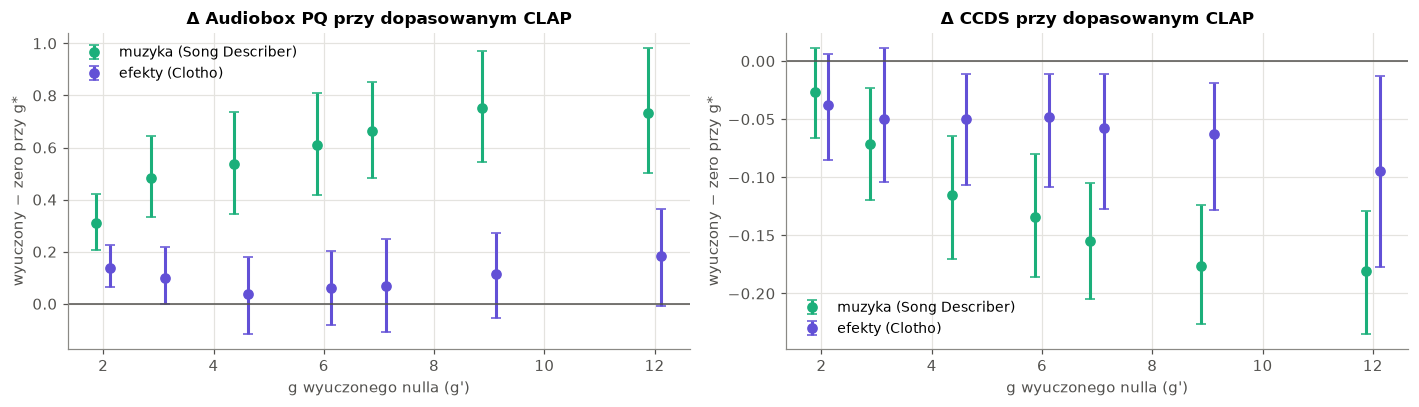

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
for ax, metric, title in [(axes[0], "PQ", "Δ Audiobox PQ przy dopasowanym CLAP"), (axes[1], "ccds", "Δ CCDS przy dopasowanym CLAP")]:
    for i, domain in enumerate(DOMAINS):
        m = matched[(matched.metric == metric) & (matched.domain == domain)]
        x = m.g_learned + (i - 0.5) * 0.25
        ax.errorbar(x, m.delta, yerr=[m.delta - m.lo, m.hi - m.delta], fmt="o", ms=6, capsize=3,
                    color=["#1baf7a", "#6250d6"][i], label=DOMAINS[domain])
    ax.axhline(0, color="#52514e", lw=1)
    ax.set(title=title, xlabel="g wyuczonego nulla (g')", ylabel="wyuczony − zero przy g*")
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

### Dodatkowo: różnice przy tym samym $g$ i FD dla muzyki

Porównanie przy *tym samym* $g$ nie rozstrzyga hipotezy (miesza efekt nulla z siłą guidance), ale pokazuje, co dokładnie zmienia wyuczony null.

**Średnia różnica wyuczony − zero przy tym samym g** (pogrubione: 95% CI wyklucza 0)

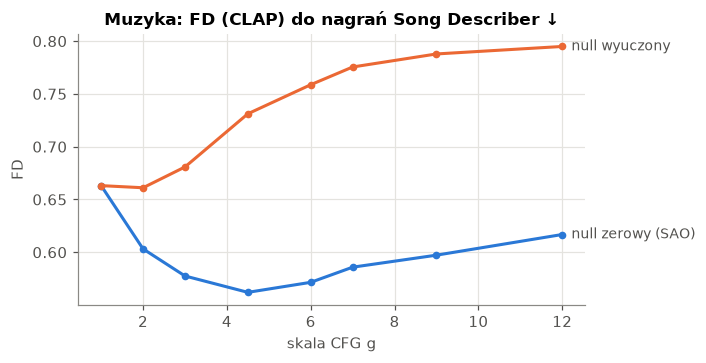

In [10]:
same = same_g_differences(table)
pivot = same.pivot_table(index=["domain", "guidance"], columns="metric", values="mean")[["clap", "PQ", "CE", "CU", "PC", "ccds"]]
display(Markdown("**Średnia różnica wyuczony − zero przy tym samym g** (pogrubione: 95% CI wyklucza 0)"))
sig = same.assign(sig=(same.lo > 0) | (same.hi < 0)).pivot_table(index=["domain", "guidance"], columns="metric", values="sig")[pivot.columns]
display(pivot.style.format("{:+.3f}").apply(lambda _: np.where(sig.astype(bool), "font-weight: bold", ""), axis=None))

fd_path = RES / "score_pilot_A/fd_music.csv"
if fd_path.exists():
    fd = pd.read_csv(fd_path)
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    for null in ("zero", "learned"):
        f = fd[fd.null == null].sort_values("guidance")
        ax.plot(f.guidance, f.fd_music, color=COLORS[null], marker="o", ms=4)
        end_label(ax, f.guidance.values, f.fd_music.values, null)
    ax.set(title="Muzyka: FD (CLAP) do nagrań Song Describer ↓", xlabel="skala CFG g", ylabel="FD")
    fig.tight_layout()

## 6. Odsłuch A/B

**Protokół** (`src/audiocfg/listen/abx.py`): 48 par muzycznych, każda z tym samym opisem i tym samym seedem. Jeden seed na prompt, losowany z seeda głównego.
- **ten sam CLAP:** wyuczony null przy $g=7$ kontra zerowy przy $g=2$ (najbliższy punkt siatki do $g^*\approx1{,}8$; zerowy ma tu minimalnie wyższy CLAP, 0,30 vs 0,28). To bezpośredni test kryterium z sekcji 1.5.
- **to samo g:** wyuczony kontra zerowy, oba przy $g=7$.

Strona A/B losowo, kolejność par losowa dla każdego słuchacza, głośność w parze wyrównana (RMS −20 dBFS, wspólny limit szczytu −1 dBFS). Odpowiedź możliwa dopiero po odsłuchaniu obu klipów, wybór wymuszony (bez „bez różnicy”). Dwa pytania: który klip brzmi lepiej jako nagranie i który lepiej pasuje do opisu. Wynik: odsetek wyborów wyuczonego nulla, 95% CI z bootstrapu po parach (średnia po słuchaczach w parze).

warunek,pytanie,learned_pref,lo,hi,listeners,answers
ten sam CLAP (g=7 vs g=2),jakość nagrania,77%,65%,88%,2,48
ten sam CLAP (g=7 vs g=2),zgodność z opisem,62%,48%,77%,2,48
to samo g = 7,jakość nagrania,62%,48%,77%,2,48
to samo g = 7,zgodność z opisem,46%,31%,60%,2,48


**Wybory wyuczonego nulla per słuchacz (na 24 pary)**

quality_learned  text_learned
listener condition                                  
JK       matched_clap               18            17
         same_g                     14            14
JakubSz  matched_clap               19            13
         same_g                     16             8

Zgodność słuchaczy w pytaniu o jakość: **60%** par.

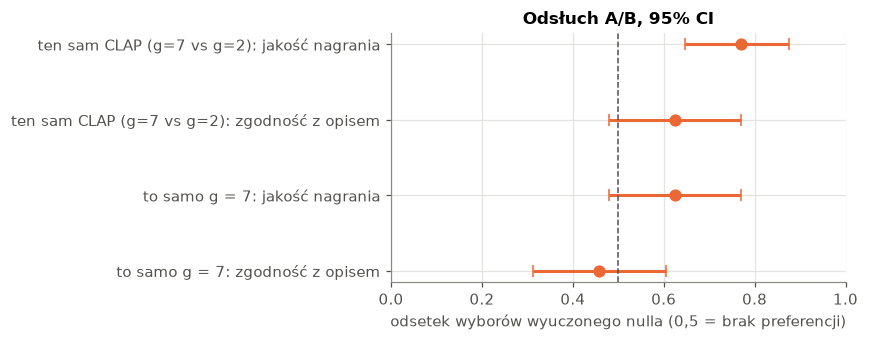

In [11]:
from audiocfg.listen.abx import load_answers, tally

pairs = pd.read_csv(RES / "listen_pilot_A/pairs.csv")
answers = load_answers(RES / "listen_pilot_A/answers")
res = tally(answers, pairs)
names = {"matched_clap": "ten sam CLAP (g=7 vs g=2)", "same_g": "to samo g = 7"}
qnames = {"quality": "jakość nagrania", "text": "zgodność z opisem"}
show = res.assign(warunek=res.condition.map(names), pytanie=res.question.map(qnames))[["warunek", "pytanie", "learned_pref", "lo", "hi", "listeners", "answers"]]
display(show.style.format({"learned_pref": "{:.0%}", "lo": "{:.0%}", "hi": "{:.0%}"}).hide(axis="index"))

d = answers.merge(pairs[["pair_id", "condition", "a_is"]], on="pair_id")
for q in ("quality", "text"):
    d[q + "_learned"] = (d[q] == "A") == (d.a_is == "learned")
per = d.groupby(["listener", "condition"])[["quality_learned", "text_learned"]].sum().astype(int)
display(Markdown("**Wybory wyuczonego nulla per słuchacz (na 24 pary)**"))
display(per)
if answers.listener.nunique() > 1:
    w = d.pivot_table(index="pair_id", columns="listener", values="quality_learned")
    agree = (w.nunique(axis=1) == 1).mean()
    display(Markdown(f"Zgodność słuchaczy w pytaniu o jakość: **{agree:.0%}** par."))

fig, ax = plt.subplots(figsize=(8, 3.2))
for i, (cond, q) in enumerate([(c, q) for c in names for q in qnames]):
    r = res[(res.condition == cond) & (res.question == q)].iloc[0]
    ax.errorbar(r.learned_pref, i, xerr=[[r.learned_pref - r.lo], [r.hi - r.learned_pref]], fmt="o", ms=7, capsize=4,
                color=COLORS["learned"])
ax.axvline(0.5, color="#52514e", lw=1, ls="--")
ax.set_yticks(range(4), [f"{names[c]}: {qnames[q]}" for c in names for q in qnames])
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="odsetek wyborów wyuczonego nulla (0,5 = brak preferencji)", title="Odsłuch A/B, 95% CI")
fig.tight_layout()

**Odczyt odsłuchu.** Przy tym samym CLAP słuchacze wyraźnie częściej wybierają wyuczony null jako lepiej brzmiący, a CI leży całe powyżej 0,5. Odsłuch potwierdza więc kierunek ΔPQ z Audiobox. Zgodność z opisem przy tym samym CLAP jest bliska losowej, tak jak powinna przy parach dobranych pod równy CLAP. Przy tym samym $g=7$ różnice nie są istotne. Kierunki zgadzają się z metrykami: wyuczony brzmi trochę lepiej, a zerowy lepiej pasuje do opisu. Słuchaczami byli członkowie zespołu, którzy znają hipotezę. To ograniczenie, które usuwa odsłuch z osobami spoza zespołu. Pary „przy tym samym CLAP” porównują wyuczony null przy $g=7$ z zerowym przy $g=2$, więc odsłuch potwierdza ten sam kontrast co ΔPQ, a nie przewagę przy tej samej skali. Powtórka B (sekcja 8) pokazuje, że przy tej samej skali przewagi PQ nie ma.

## 7. Wnioski, kiedy działa, dalsze kroki

**Krótko: hipoteza w zapisanej postaci się nie potwierdza, ani w pilotażu A, ani w powtórce B.** Wyuczony null przesuwa model w stronę prostszej, mniej zgodnej z opisem i mniej różnorodnej muzyki. Przewaga PQ „przy tym samym CLAP” powtarza się, ale powtórka pokazuje, że wynika głównie z tego, że wyuczony null nie osiąga wysokiego CLAP, a nie z lepszej jakości przy dowolnym $g$.

| Warunek kryterium (sekcja 1.5) | Muzyka A | Muzyka B | Efekty A | Efekty B |
|---|---|---|---|---|
| 1. ΔPQ > 0 przy tym samym CLAP ($g'\in\{6,7,9\}$) | ✅ | ✅ +0,36 do +0,42 | ❌ | ❌ CI zawiera 0 |
| 2. ΔCCDS ≥ −δ | ❌ | ❌ −0,20 do −0,23 (δ = 0,07) | ❌ | ❌ −0,08 do −0,09 (δ = 0,06) |
| 3. FD w tym samym kierunku co PQ | ❌ | ❌ FD 0,80–0,84 wobec minimum zerowego 0,59 | — | — |
| 4. powtórka na nowych promptach i seedach | | ❌ żaden $g'$ nie spełnia 1–3 | | ❌ |
| 5. odsłuch zgodny co do kierunku | ✅ (A) | — (odsłuch tylko A) | — | — |

1. **Krok 1 (P0) jest spełniony.** Wyuczony null obniża stratę odszumiania na niewidzianych artystach (+0,00081, 95% CI [0,00047; 0,00117]), czyli około 60% zysku, jaki daje prawdziwy opis.
2. **Przewaga PQ przy tym samym CLAP powtarza się, ale nie jest przewagą jakości w ogóle.**
   - W A wyuczony null osiągał PQ 7,95, a zerowy nie przekraczał 7,77 przy żadnym $g$.
   - W B tak nie jest: maksimum PQ jest praktycznie równe (7,93 wobec 7,95), a przy tym samym $g\ge3$ zerowy ma nawet trochę wyższe PQ (różnice w granicach CI).
   - Dodatni ΔPQ przy tym samym CLAP bierze się stąd, że maksymalny CLAP wyuczonego nulla w muzyce (≈0,29 w A, ≈0,32 w B) zerowy osiąga już przy $g^*\approx1{,}5$–$1{,}9$, gdzie jego PQ jest jeszcze niskie.
3. **Koszty powtarzają się w obu zbiorach:**
   - zgodność z opisem (CLAP przy $g=7$: 0,31 wobec 0,42 w B),
   - różnorodność (CCDS),
   - złożoność muzyki (PC ≈2,8 wobec ≈3,9 przy $g=7$ w B),
   - odległość od prawdziwej muzyki (FD).
4. **Odporność na przesterowanie powtarza się tylko dla efektów.** W B przy $g=7$ odsetek próbek |x|>1 dla efektów wynosi 0,4% z wyuczonym nullem wobec 1,6% z zerowym. W muzyce B różnicy nie ma.

**Kiedy działa (A i B razem).**
- Wyuczony null nie daje lepszej jakości przy tej samej skali $g$, w sposób powtarzalny tylko ogranicza przesterowanie efektów przy dużym $g$.
- W muzyce działa jak inny punkt pracy: prostszy i czystszy sygnał kosztem zgodności z opisem i różnorodności.
- Zysk PQ widoczny w A przy tym samym $g$ (+0,17 do +0,34) nie powtórzył się w B (−0,07 do −0,03, CI zawiera 0), więc był zależny od promptów.

**Dalsze kroki.**
1. Porównanie nulli przy tej samej różnorodności (CCDS) i złożoności (PC) zamiast przy tym samym CLAP, na istniejących danych A i B.
2. Słabszy null $\alpha N$, $\alpha\in(0,1)$, jako drugie pokrętło obok $g$. $\alpha$ wybieramy na A, a oceniamy na B (oba zbiory są już w repo).
3. Null uczony z warunkiem tekstowym w stracie (np. różnica strat z opisem i bez), żeby nie ciągnął modelu w stronę „typowej muzyki” kosztem zgodności z opisem.
4. Odsłuch trzeciego członka zespołu i osób spoza zespołu, które nie znają hipotezy, także na parach z B.
5. Dopiero po powtarzalnej poprawie: drugi generator i wariant ReNeg (null uczony pod ocenę generacji) z niezależnym sędzią końcowym.

Cel publikacyjny tylko przy wyniku, który przejdzie kryterium na nowym zbiorze: ISMIR (muzyka) lub ICASSP. Obecny wynik nadaje się najwyżej na raport negatywny.

**Powtarzalność oceny.** Dwa niezależne przeliczenia metryk na Kaggle dały identyczne PQ/CE/CU/PC. CLAP różnił się o medianę 1e-5 (99. percentyl 0,002, maks. 0,03), co wynika z niedeterminizmu kerneli GPU. To o rząd wielkości mniej niż badane efekty. Od następnego przebiegu CLAP liczy się z deterministycznymi algorytmami cuDNN.

## 8. Powtórka: nowe prompty i nowe seedy

**Co się zmienia względem pilotażu A:**
- **prompty:** kolejne 24 muzyczne i 24 efektów z zamrożonej listy (`rank` 24–47 w `data/eval_prompts.csv`), żadnego wspólnego z A,
- **seedy:** zbiór B, żadnego wspólnego z A.

Null, siatka $g$, sampler, metryki i analiza są te same co w A (`configs/sweep_pilot_B.yaml`, `configs/score_pilot_B.yaml`). Kryterium z sekcji 1.5, łącznie z δ, jest zapisane w `configs/criterion_pilot_B.yaml` i zacommitowane, zanim powstał pierwszy klip B.

Poniżej werdykt warunków 1–3 dla obu zbiorów. Rozstrzyga B, bo δ wyznaczyliśmy z wyników A.

**Pilotaż A (prompty 0–23, seedy A)**

domain,g,g* zerowego,1. PQ lepsze,2. CCDS nie gorsze,3. FD zgodne,przewaga
music,6,1.84,✅,❌,❌,❌
music,7,1.76,✅,❌,❌,❌
music,9,1.73,✅,❌,❌,❌
sfx,6,3.85,❌,❌,—,❌
sfx,7,3.44,❌,❌,—,❌
sfx,9,3.54,❌,❌,—,❌


**Powtórka B (prompty 24–47, seedy B)**

domain,g,g* zerowego,1. PQ lepsze,2. CCDS nie gorsze,3. FD zgodne,przewaga
music,6,1.47,✅,❌,❌,❌
music,7,1.46,✅,❌,❌,❌
music,9,1.45,✅,❌,❌,❌
sfx,6,3.25,❌,❌,—,❌
sfx,7,3.98,❌,❌,—,❌
sfx,9,4.14,❌,❌,—,❌


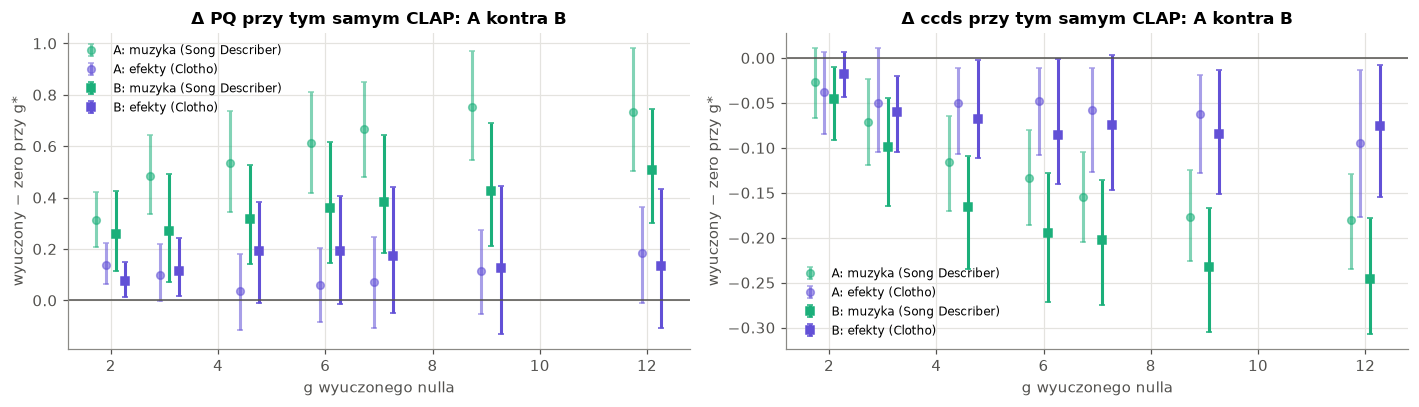

In [12]:
def show_verdict(path, title):
    v = pd.read_csv(path)
    mark = lambda x: "—" if pd.isna(x) else ("✅" if x in (True, "True") else "❌")
    for col in ("pq_better", "ccds_not_worse", "fd_agrees", "advantage"):
        v[col] = v[col].map(mark)
    v = v.rename(columns={"g_learned": "g", "g_star_zero": "g* zerowego", "pq_better": "1. PQ lepsze",
                          "ccds_not_worse": "2. CCDS nie gorsze", "fd_agrees": "3. FD zgodne", "advantage": "przewaga"})
    display(Markdown(f"**{title}**"))
    display(v.style.format({"g* zerowego": "{:.2f}"}).hide(axis="index"))

show_verdict(RES / "analysis_pilot_A/verdict.csv", "Pilotaż A (prompty 0–23, seedy A)")
vb = RES / "analysis_pilot_B/verdict.csv"
if vb.exists():
    show_verdict(vb, "Powtórka B (prompty 24–47, seedy B)")
    mb = pd.read_csv(RES / "analysis_pilot_B/matched_clap.csv")
    ma = pd.read_csv(RES / "analysis_pilot_A/matched_clap.csv")
    both = pd.concat([ma.assign(zbiór="A"), mb.assign(zbiór="B")])
    both = both[both.metric.isin(["PQ", "ccds"])]
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    for ax, metric in zip(axes, ["PQ", "ccds"]):
        for j, (zb, dom) in enumerate([(z, d) for z in "AB" for d in DOMAINS]):
            m = both[(both.metric == metric) & (both.zbiór == zb) & (both.domain == dom)]
            x = m.g_learned + (j - 1.5) * 0.18
            ax.errorbar(x, m.delta, yerr=[m.delta - m.lo, m.hi - m.delta], fmt="o" if zb == "A" else "s", ms=5,
                        capsize=2, color=["#1baf7a", "#6250d6"][j % 2], alpha=0.55 if zb == "A" else 1,
                        label=f"{zb}: {DOMAINS[dom]}")
        ax.axhline(0, color="#52514e", lw=1)
        ax.set(title=f"Δ {metric} przy tym samym CLAP: A kontra B", xlabel="g wyuczonego nulla", ylabel="wyuczony − zero przy g*")
        ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
else:
    display(Markdown("Wyniki powtórki B nie są jeszcze w repo. Po ich pobraniu: `audiocfg analyze --score-dir results/score_pilot_B --out results/analysis_pilot_B --criterion configs/criterion_pilot_B.yaml`, a potem ponowne wykonanie notatnika."))

**Odczyt powtórki.** Kryterium nie jest spełnione przy żadnym $g'\in\{6,7,9\}$, w żadnej domenie. Wzorzec z A powtarza się: w muzyce ΔPQ przy tym samym CLAP jest dodatni z CI powyżej 0, a ΔCCDS i FD są wyraźnie gorsze. Efekty nie dają istotnej różnicy PQ. Nowa obserwacja z B: przy tej samej skali $g$ wyuczony null nie ma wyższego PQ w muzyce (tabela `results/analysis_pilot_B/same_g.csv`), więc przewaga z A przy tym samym $g$ zależała od promptów. Wnioski z obu zbiorów są w sekcji 7.